In [1]:
!pip install ultralytics fastapi uvicorn python-multipart opencv-python-headless pandas matplotlib requests -q

In [2]:
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import json
import uuid

from ultralytics import YOLO
from PIL import Image
from google.colab import files
from IPython.display import display

print("Libraries imported successfully")
print("CUDA Available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully
CUDA Available: False


In [3]:
model = YOLO("yolov8n.pt")

print("Model loaded successfully")
print("Model: YOLOv8 Nano")
print("Task:", model.task)

Model loaded successfully
Model: YOLOv8 Nano
Task: detect


Saving Screenshot 2026-11-13 122011.png to Screenshot 2026-11-13 122011.png
Saving Screenshot 2026-11-13 122024.png to Screenshot 2026-11-13 122024.png


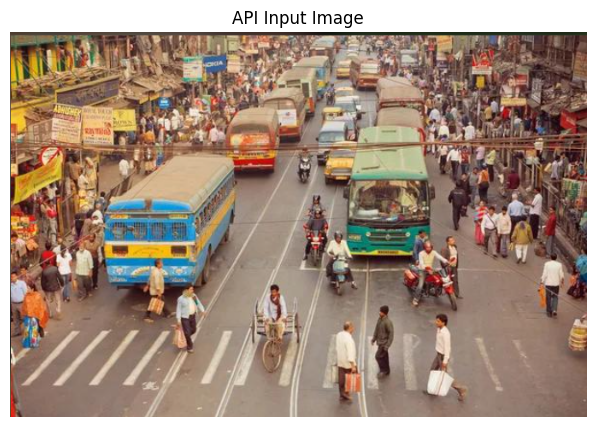

Request ID: 271f0650-e6d2-4eec-86c4-2bfeb2ba6ee1
Image: Screenshot 2026-11-13 122011.png
Image Dimensions: (451, 675, 3)
Input received successfully


In [4]:
uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.title("API Input Image")
plt.axis("off")
plt.show()

print("Request ID:", str(uuid.uuid4()))
print("Image:", image_path)
print("Image Dimensions:", image.shape)
print("Input received successfully")

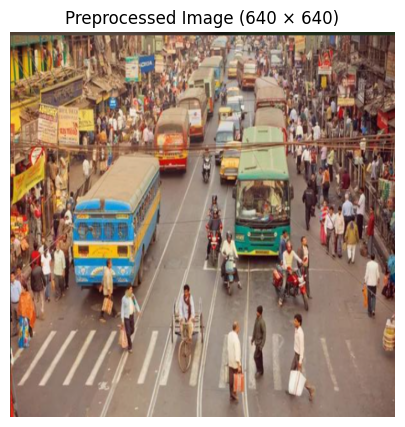

Original Dimensions: 675 x 451
Processed Dimensions: (640, 640, 3)
Preprocessing Time: 11.6 ms


In [5]:
start_preprocessing = time.time()

original_height, original_width = image.shape[:2]

processed_image = cv2.resize(image, (640, 640))

normalized_image = processed_image.astype(np.float32) / 255.0

preprocessing_time = time.time() - start_preprocessing

plt.figure(figsize=(8, 5))
plt.imshow(normalized_image)
plt.title("Preprocessed Image (640 × 640)")
plt.axis("off")
plt.show()

print("Original Dimensions:", original_width, "x", original_height)
print("Processed Dimensions:", processed_image.shape)
print("Preprocessing Time:", round(preprocessing_time * 1000, 2), "ms")

In [6]:
start_inference = time.time()

results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

inference_time = time.time() - start_inference

print("Model execution completed")
print("Inference Time:", round(inference_time * 1000, 2), "ms")

Model execution completed
Inference Time: 7483.65 ms


In [7]:
detections = []

for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        detections.append({
            "Object": model.names[class_id],
            "Confidence": round(confidence, 4),
            "X1": round(x1, 2),
            "Y1": round(y1, 2),
            "X2": round(x2, 2),
            "Y2": round(y2, 2)
        })

detection_df = pd.DataFrame(detections)

display(detection_df)

print("Total Objects Detected:", len(detections))

,Object,Confidence,X1,Y1,X2,Y2
0,bus,0.9039,108.37,140.13,268.58,301.64
1,person,0.6890,617.69,256.83,649.25,334.80
2,person,0.6838,192.95,295.56,229.35,374.29
3,person,0.6734,421.91,319.99,449.58,406.04
4,person,0.6686,156.96,266.54,183.85,334.00
5,person,0.6611,35.60,260.29,64.61,336.41
6,bus,0.6354,391.79,112.41,494.73,262.88
7,person,0.6136,370.48,337.91,408.02,433.69
8,car,0.5846,367.17,137.87,405.11,178.40
9,person,0.5504,294.90,294.34,324.90,360.91


Total Objects Detected: 27


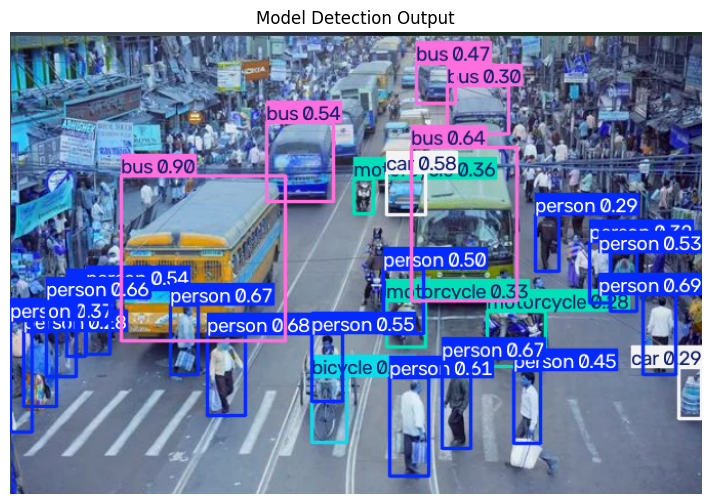

In [8]:
annotated_image = results[0].plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 6))
plt.imshow(annotated_image)
plt.title("Model Detection Output")
plt.axis("off")
plt.show()

In [9]:
response = {
    "status": "success",
    "request_id": str(uuid.uuid4()),
    "model": "YOLOv8n",
    "inference_time_ms": round(inference_time * 1000, 2),
    "preprocessing_time_ms": round(preprocessing_time * 1000, 2),
    "total_detections": len(detections),
    "detections": detections
}

print(json.dumps(response, indent=4))

{
    "status": "success",
    "request_id": "8a523bb6-e3fd-412e-977d-d25b2d82ca0e",
    "model": "YOLOv8n",
    "inference_time_ms": 7483.65,
    "preprocessing_time_ms": 11.6,
    "total_detections": 27,
    "detections": [
        {
            "Object": "bus",
            "Confidence": 0.9039,
            "X1": 108.37,
            "Y1": 140.13,
            "X2": 268.58,
            "Y2": 301.64
        },
        {
            "Object": "person",
            "Confidence": 0.689,
            "X1": 617.69,
            "Y1": 256.83,
            "X2": 649.25,
            "Y2": 334.8
        },
        {
            "Object": "person",
            "Confidence": 0.6838,
            "X1": 192.95,
            "Y1": 295.56,
            "X2": 229.35,
            "Y2": 374.29
        },
        {
            "Object": "person",
            "Confidence": 0.6734,
            "X1": 421.91,
            "Y1": 319.99,
            "X2": 449.58,
            "Y2": 406.04
        },
        {
         

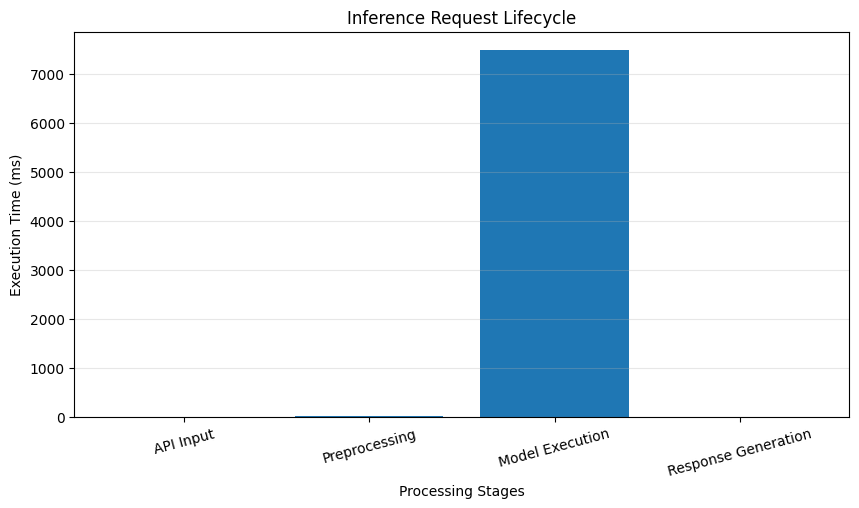

INFERENCE LIFECYCLE COMPLETED
Input → Preprocessing → Model → Response


In [10]:
stages = [
    "API Input",
    "Preprocessing",
    "Model Execution",
    "Response Generation"
]

times = [
    0,
    preprocessing_time * 1000,
    inference_time * 1000,
    0
]

plt.figure(figsize=(10, 5))
plt.bar(stages, times)

plt.title("Inference Request Lifecycle")
plt.ylabel("Execution Time (ms)")
plt.xlabel("Processing Stages")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()

print("INFERENCE LIFECYCLE COMPLETED")
print("Input → Preprocessing → Model → Response")